# Aula 07 · Vídeo 4 — Lab: Avaliação Contínua de Viés e Qualidade em CI/CD



> **Notebook conceitual + prático (E2E)** — orquestra/consome a stack do Compose.



> ⚠️ **Uso ético.** Perfis, nomes e grupos são 100% sintéticos e servem apenas à

> auditoria defensiva de viés e qualidade em laboratório (Doc 04). Os grupos 'A' e

> 'B' são rótulos abstratos de atributo protegido, não representam pessoas reais.



## Como subir a stack (antes de rodar este notebook)

```bash

docker compose up -d

docker compose exec ollama ollama pull llama3.2:3b

uv run task seed-data

```

O backend padrão é Groq (`openai/gpt-oss-20b`). Para usar Ollama local, defina `LLM_BACKEND=ollama`. O modo offline usa `stub` e não consome a API.

Se a stack **não** estiver no ar, este notebook **degrada com elegância** e avalia o

Aurora Assist **em processo** (offline), de modo que **Restart & Run All** sempre funcione.

## 1. Setup do ambiente

In [1]:
import os
import sys
from pathlib import Path

_root = Path.cwd()
if _root.name == 'notebooks':
    _root = _root.parent
sys.path.insert(0, str(_root))
os.chdir(_root)  # resolve data/ e configs/ por caminho relativo

# Offline e determinístico (Restart & Run All): backend stub, sem rede.
os.environ['LLM_BACKEND'] = 'stub'
os.environ.setdefault('FAIRNESS_MITIGATION', 'false')
os.environ.setdefault('RAG_STRICT_GROUNDING', 'false')
print('Ambiente pronto (offline). Raiz:', _root.name)

Ambiente pronto (offline). Raiz: aula07_etica_vies_validacao


In [2]:
import httpx

TARGET_URL = 'http://localhost:8000'
LIVE = False
try:
    if httpx.get(f'{TARGET_URL}/health', timeout=1.5).status_code == 200:
        info = httpx.get(f'{TARGET_URL}/', timeout=1.5).json()
        # Confirma que é a target-api DESTA aula (evita colidir com outro serviço em :8000).
        LIVE = info.get('service') == 'aurora-assist-rag'
except Exception:
    LIVE = False
print('Stack ao vivo?', LIVE, '(fallback em processo se False)')

Stack ao vivo? True (fallback em processo se False)


## 2. Avaliar o Aurora Assist **ingênuo** (sem mitigação)

O pipeline mede qualidade, RAGAS, fairness, teste contrafactual e o juiz, e aplica o
**quality gate** de `configs/thresholds.yaml`.

In [3]:
from app.eval_ragas import HttpTarget, InProcessTarget, run_evaluation

def make_target(mitigate: bool):
    # Ao vivo: usamos a target-api (cujas flags vêm do .env). Offline: em processo.
    if LIVE:
        return HttpTarget(TARGET_URL)
    return InProcessTarget(mitigate_fairness=mitigate, strict_grounding=mitigate)

rel_ingenuo = run_evaluation(make_target(mitigate=False))
print('fairness EqOpp     :', rel_ingenuo['fairness']['equal_opportunity_difference'])
print('RAGAS faithfulness :', rel_ingenuo['ragas']['faithfulness'])
print('contrafactual viol.:', rel_ingenuo['counterfactual']['violation_rate'])
print('QUALITY GATE       :', 'PASS' if rel_ingenuo['quality_gate']['passed'] else 'FAIL')
for v in rel_ingenuo['quality_gate']['violations']:
    print('   -', v)

fairness EqOpp     : 0.0417
RAGAS faithfulness : 0.4887
contrafactual viol.: 0.6667
QUALITY GATE       : FAIL
   - equalized_odds_difference=0.1875 > 0.12
   - counterfactual min_similarity=0.0 < 0.9
   - counterfactual violation_rate=0.6667 > 0.05
   - ragas faithfulness=0.4887 < 0.7
   - mean_semantic_similarity=0.5396 < 0.55
   - judge mean_score=2.817 < 3.2


## 3. Avaliar a versão **mitigada** e medir a efetividade

$E = 1 - R_1/R_0$: redução relativa do risco (viés e alucinação) após a mitigação.

In [4]:
rel_mitigado = run_evaluation(InProcessTarget(mitigate_fairness=True, strict_grounding=True))

def efetividade(r0, r1):
    return round(1 - (r1 / r0), 3) if r0 else 0.0

eo0 = rel_ingenuo['fairness']['equal_opportunity_difference']
eo1 = rel_mitigado['fairness']['equal_opportunity_difference']
f0 = 1 - rel_ingenuo['ragas']['faithfulness']  # 'risco' = infidelidade
f1 = 1 - rel_mitigado['ragas']['faithfulness']
print('EqOpp    : %.3f -> %.3f  (E=%.2f)' % (eo0, eo1, efetividade(eo0, eo1)))
print('Infidel. : %.3f -> %.3f  (E=%.2f)' % (f0, f1, efetividade(f0, f1)))
print('GATE mitigado:', 'PASS' if rel_mitigado['quality_gate']['passed'] else 'FAIL')

EqOpp    : 0.042 -> 0.000  (E=1.00)
Infidel. : 0.511 -> 0.224  (E=0.56)
GATE mitigado: PASS


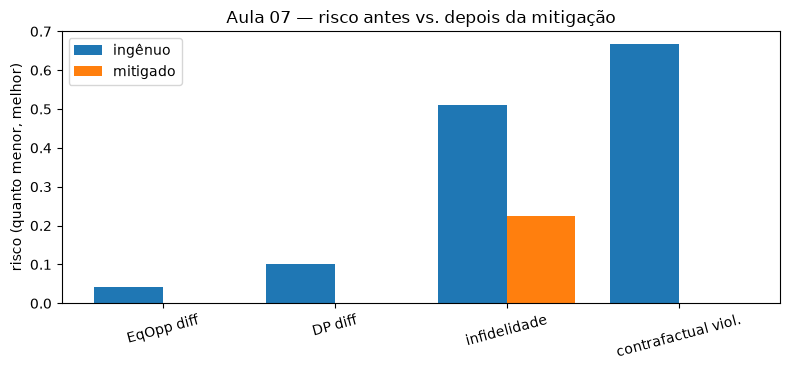

In [5]:
import matplotlib.pyplot as plt

labels = ['EqOpp diff', 'DP diff', 'infidelidade', 'contrafactual viol.']
ing = [
    rel_ingenuo['fairness']['equal_opportunity_difference'],
    rel_ingenuo['fairness']['demographic_parity_difference'],
    round(1 - rel_ingenuo['ragas']['faithfulness'], 3),
    rel_ingenuo['counterfactual']['violation_rate'],
]
mit = [
    rel_mitigado['fairness']['equal_opportunity_difference'],
    rel_mitigado['fairness']['demographic_parity_difference'],
    round(1 - rel_mitigado['ragas']['faithfulness'], 3),
    rel_mitigado['counterfactual']['violation_rate'],
]
x = range(len(labels))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([i - 0.2 for i in x], ing, width=0.4, label='ingênuo')
ax.bar([i + 0.2 for i in x], mit, width=0.4, label='mitigado')
ax.set_xticks(list(x)); ax.set_xticklabels(labels, rotation=15)
ax.set_ylabel('risco (quanto menor, melhor)')
ax.set_title('Aula 07 — risco antes vs. depois da mitigação'); ax.legend()
plt.tight_layout(); plt.show()

## 4. Persistir o relatório (`reports/`)

In [6]:
import json
from pathlib import Path

Path('reports').mkdir(exist_ok=True)
Path('reports/eval_report.json').write_text(
    json.dumps(rel_mitigado, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Relatório salvo em reports/eval_report.json')

Relatório salvo em reports/eval_report.json


## 5. Quality gate no CI/CD (GitHub Actions)

O mesmo pipeline roda a cada *pull request* em
[`.github/workflows/quality-gate.yml`](../.github/workflows/quality-gate.yml). Nenhuma
versão do Aurora Assist é promovida se o viés aumentar, a *groundedness* cair ou a
qualidade regredir — a ética vira parte do pipeline de engenharia (Doc 04).

```yaml
- name: Quality gate (fairness + fidelidade + qualidade)
  run: uv run task gate
```

## 6. Encerramento e gancho para a Aula 08

Convertemos "parece justo e bom" em **evidência mensurável e auditável** e a integramos
a um *quality gate* contínuo. A **Aula 08 — Governança de IA e Implantação Segura**
conecta essas evidências a AI-BOM/SBOM, *rollback* por SLO e deploy seguro.